## Integrated CA2 Ciaran Lynch sba26096

Ths is an integrated CA2 assignment, for the subjects of:  
1.  Data Preparation  
2.  Statistical Techniques for DA  
3.  Machine Learning  

Background:

Suppose you are working as a Data Analyst or Data Scientist at a Renewable Energy Market and Grid Planning Consultancy in Ireland. The company has provided you with a synthetic dataset containing projected solar photovoltaic (PV) demand observations across Irish counties for the future planning period 2027 -2034. This reflects Ireland's continued expansion of solar PV and the need to understand where future installation demand may be strongest.
The dataset includes economic, market, technical, infrastructure, and policy-related indicators, such as average household income, electricity price levels, solar irradiance, roof suitability, grid accessibility, synthetic SEAI grant support, installation cost levels, planning constraints, customer segment, and forecast year.
It also includes
●	The Solar PV Demand Level (Low, Average, High)
●	The Projected Annual Solar PV Demand (kWp) for each observation

We have been provided with an excel file called CA2_dataset.  For the purpose of uploading to Python, I will create a csv version and continue working on the excel file.  
We also have a Data Dictionary called: Data Dictionary - Solar Panels. I created a csv version and I will Read this into Python as CA2_Data_DIctionary.csv



Add Python Libraries

In [691]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np

Open the Data Dictionary csv version

In [692]:
df_Dict = pd.read_csv("CA2_Data_Dictionary.csv")

In [693]:
df_Dict

,Variable,Data Type,Unit,Description,Expected Values / Range
0,County,Categorical,NaN,Irish county associated with the prospective s...,26 counties of the Republic of Ireland
1,Forecast_Year,Integer,Year,Future planning year for the synthetic solar P...,2027 - 2034
2,Local_Mean_Household_Disposable_Income_EUR,Numeric,EUR/year,Synthetic estimate of mean annual disposable h...,"Typically EUR 35,000 - 125,000"
3,Electricity_Cost_Index,Numeric,Index,Synthetic electricity-cost pressure index for ...,Typically 65 - 150; 100 = scenario baseline
4,Solar_Resource_Index,Numeric,Score,Relative solar-resource potential for the obse...,1 - 10; higher = stronger solar resource
5,Site_Suitability_Score,Numeric,Score,Suitability of the prospective site for solar ...,1 - 10; higher = more suitable
6,Grid_Connection_Accessibility_Score,Numeric,Score,Relative ease of electricity-network access or...,1 - 10; higher = easier access or connection
7,Scenario_Grant_Support_EUR,Numeric,EUR,Synthetic future grant or support amount used ...,Non-negative EUR; varies by customer segment
8,Installation_Cost_Index,Numeric,Index,Relative solar PV installation-cost index. A v...,Typically 55 - 145; 100 = scenario baseline
9,Planning_and_Site_Constraint_Index,Numeric,Score,"Synthetic constraint index covering planning, ...",1 - 10; higher = stronger constraints


Read in the CA2_Dataset csv file, created from the main excel file.  
Working with the excel file and running an UNIQUE formula, it was evident that there is typos with the County names.  I will fix this issue once the dataset is loaded.  


In [694]:
df = pd.read_csv("CA2_Dataset.csv")

In [695]:
df.head(5)

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp
0,Cork,2028.0,"€65,862.18",89.99,8.13,5.61,8.08,"€1,908.61",81.96,5.67,Residential,High,8.45
1,Mayo,2031.0,"€67,500.75",84.20,4.81,7.66,5.06,"€15,663.54",113.48,1.96,SME,Average,101.80
2,Laois,2030.0,"€79,701.35",111.98,6.75,5.95,8.89,"€1,649.07",99.59,4.12,Residential,Average,4.70
3,Kildare,2033.0,"€87,871.20",101.35,7.28,5.15,6.05,"€1,266.87",98.49,6.65,Residential,Average,10.30
4,Dublin,2030.0,"€105,318.63",98.78,6.88,9.11,9.47,"€8,999.65",100.10,7.37,SME,High,150.00


In [696]:
df.tail(5)

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp
2075,Dublin,2032.0,"€109,767.78",128.31,7.14,6.23,7.57,"€1,323.28",89.34,6.00,Residential,High,9.59
2076,Dublin,2030.0,"€88,591.06",108.95,6.60,6.44,8.47,"€1,327.34",90.11,7.84,Residential,Average,7.97
2077,Meath,2034.0,"€91,467.03",94.46,6.98,5.70,7.43,"€1,293.27",78.95,4.28,Residential,High,10.46
2078,Cork,2030.0,"€83,959.35",92.18,5.51,5.00,8.70,"€1,432.16",97.46,6.56,Residential,Average,10.59
2079,Cork,2033.0,"€78,352.80",99.88,8.37,2.63,8.29,"€1,596.02",82.04,6.78,Residential,Average,9.60


In [697]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2080 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        2059 non-null   str    
 1   Forecast_Year                                 2059 non-null   float64
 2   Local_Mean_Household_Disposable_Income_EUR    2059 non-null   str    
 3   Electricity_Cost_Index                        2059 non-null   float64
 4   Solar_Resource_Index                          2059 non-null   float64
 5   Site_Suitability_Score                        2059 non-null   float64
 6   Grid_Connection_Accessibility_Score           2059 non-null   float64
 7   Scenario_Grant_Support_EUR                    2059 non-null   str    
 8   Installation_Cost_Index                       2059 non-null   float64
 9   Planning_and_Site_Constraint_Index            2059 non-null   float64
 10 

On review of the Excel data:

Forecast_Year is to be converted to an Integer.  
    
Local_Mean_Household_Disposable_Income_EUR is to be converted to a Float.  

Scenario_Grant_Support_EUR is to be converted to a Float.  

After reviewing, i was unable to apply the .apply(pd.to_numeric, errors="coerce").astype(float) methods on Local_Mean_Household_Disposable_Income_EUR and Scenario_Grant_Support_EUR.  
    
Both of these were listed as strings and had "€" symbol and "," symbols inside the string value, that needed to be removed.  
In order to fix the issues, i had to run a str.replace for the "€" and "," symbols, before converting to floats.  See code listed below

In [698]:
df["Forecast_Year"] = df["Forecast_Year"].apply(pd.to_numeric, errors="coerce").astype("Int64")

In [699]:
df["Local_Mean_Household_Disposable_Income_EUR"] = (
    df["Local_Mean_Household_Disposable_Income_EUR"].str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False).astype(float)
)

In [700]:
df["Scenario_Grant_Support_EUR"] = (
    df["Scenario_Grant_Support_EUR"].str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False).astype(float)
)

In [701]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2080 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        2059 non-null   str    
 1   Forecast_Year                                 2059 non-null   Int64  
 2   Local_Mean_Household_Disposable_Income_EUR    2059 non-null   float64
 3   Electricity_Cost_Index                        2059 non-null   float64
 4   Solar_Resource_Index                          2059 non-null   float64
 5   Site_Suitability_Score                        2059 non-null   float64
 6   Grid_Connection_Accessibility_Score           2059 non-null   float64
 7   Scenario_Grant_Support_EUR                    2059 non-null   float64
 8   Installation_Cost_Index                       2059 non-null   float64
 9   Planning_and_Site_Constraint_Index            2059 non-null   float64
 10 

****

Check for duplicates and remove

In [702]:
df.shape

(2080, 13)

In [703]:
duplicateRows = df[df.duplicated()]
print("The number of duplicate rows = ", len(duplicateRows))

The number of duplicate rows =  10


In [704]:
df.drop_duplicates(inplace = True) 

In [705]:
df.shape

(2070, 13)

In [706]:
Original_Shape = len(df["County"])

Original_Shape

2070

Carry Out Analysis of Solar_PV_Demand_Level  

Per dictionary, this is the Target variable and should have 3 categories of:
    Low
    Average
    High

In [707]:
df["Solar_PV_Demand_Level"].unique()

<ArrowStringArray>
['High', 'Average', 'Low', 'Medium', nan, 'NONE', 'Very High', 'high']
Length: 8, dtype: str

In [708]:
print(df["Solar_PV_Demand_Level"].value_counts(dropna=False))

Solar_PV_Demand_Level
Average      983
Low          533
High         529
NaN           21
Medium         1
NONE           1
Very High      1
high           1
Name: count, dtype: int64


In [709]:
df["Solar_PV_Demand_Level"] = df["Solar_PV_Demand_Level"].replace(
    {
        "Medium": "Average",
        "Very High": "High",
        "high" : "High",
        "NONE" : np.nan,        
    }
)

The categorical values of the Solar_PV_Demand_Level have been replaced and the NONE value was converted to nan using numpy.  This has now left 22 missing values


In [710]:
print(df["Solar_PV_Demand_Level"].value_counts(dropna=False))

Solar_PV_Demand_Level
Average    984
Low        533
High       531
NaN         22
Name: count, dtype: int64


In [711]:
df.loc[
    df["Solar_PV_Demand_Level"].isna(),
    ["Solar_PV_Demand_Level", "County", "Forecast_Year", "Electricity_Cost_Index", "Customer_Segment", "Local_Mean_Household_Disposable_Income_EUR"]
    ]

,Solar_PV_Demand_Level,County,Forecast_Year,Electricity_Cost_Index,Customer_Segment,Local_Mean_Household_Disposable_Income_EUR
158,NaN,Limerick,2022,108.42,Residential,61922.10
161,NaN,Cork,2032,120.62,Residential,80616.04
277,NaN,Roscommon,2033,112.23,SME,63802.98
674,NaN,Wicklow,2028,107.31,Farm,84490.97
707,NaN,Cork,2033,99.00,Residential,84677.02
791,NaN,Cork,2028,112.49,SME,69257.98
1004,NaN,Monaghan,2028,101.85,Residential,58980.17
1011,NaN,Cork,2029,111.84,Residential,49549.08
1140,NaN,Dublin,2034,87.95,SME,104812.38
1346,NaN,Dublin,2028,93.06,Residential,87221.92


In [712]:
df.loc[
    df["Solar_PV_Demand_Level"] == "Average",
    "Electricity_Cost_Index"].median()

np.float64(103.42)

In [713]:
df.loc[
    df["Solar_PV_Demand_Level"] == "High",
    "Electricity_Cost_Index"].median()

np.float64(106.775)

source  https://www.kdnuggets.com/masked-arrays-in-numpy-to-handle-missing-data.  

As Solar_PV_Demand_Level is the Target variable, i will not drop any values.  Values will be imputed on a rule based approach
    
Create a mask for the missing values for Solar_PV_Demand_Level
I will take the median values based on Electricity_Cost_Index and impute a value for Solar_PV_Demand_Level, based on either High, Average or Low

In [714]:
mask = df["Solar_PV_Demand_Level"].isna()

High = df.loc[
    df["Solar_PV_Demand_Level"] == "High",
    "Electricity_Cost_Index"].median()

Average = df.loc[
    df["Solar_PV_Demand_Level"] == "Average",
    "Electricity_Cost_Index"].median()

df.loc[mask, "Solar_PV_Demand_Level"] = np.select(
    [
        df.loc[mask, "Electricity_Cost_Index"] >= High,
        df.loc[mask, "Electricity_Cost_Index"] >= Average

    ] ,
    [
        "High",
        "Average"
    ], default = "Low"  

)


In [715]:
df.loc[
    df["Solar_PV_Demand_Level"].isna(),
    ["Solar_PV_Demand_Level", "County", "Forecast_Year", "Electricity_Cost_Index", "Customer_Segment", "Local_Mean_Household_Disposable_Income_EUR"]
    ]

,Solar_PV_Demand_Level,County,Forecast_Year,Electricity_Cost_Index,Customer_Segment,Local_Mean_Household_Disposable_Income_EUR


In [716]:
# Spot check to see if the record updated correctly
df.loc[ [791,1471, 2055], ["Solar_PV_Demand_Level", "Electricity_Cost_Index", "County", "Forecast_Year"] ]

,Solar_PV_Demand_Level,Electricity_Cost_Index,County,Forecast_Year
791,High,112.49,Cork,2028
1471,Low,101.73,Wicklow,2029
2055,Low,94.93,Kildare,2032


Analysis of Solar_PV_Demand_Level.  

On review of this column, it was discovered that we had 22 missing rows after replacing incorrect values.  
In order to impute values, I searched for the median High value and median average value of the Electricity_Cost_Index.  
The variable "High" had a median value of 106.77 or greater and the "Average" variable had a value of 103.44 or higher, with the default being set as "Low".  
The above formula assigned a value to Solar_PV_Demand_Level, based on the median value of that rows Electricity_Cost_Index.  the values were imputed as either High, Average or Low.  

I beleive this was an appropriate approach, rather than deleting 22 valuable rows of data


*****

In [717]:
df.isnull().sum()

County                                          21
Forecast_Year                                   21
Local_Mean_Household_Disposable_Income_EUR      21
Electricity_Cost_Index                          21
Solar_Resource_Index                            21
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                21
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

Note that quite a number of Rows have exactly 21 missing rows of data.

Full Disclosure: I have moved the analysis of Forecast_Years to the beginning of the anlaysis, for this reason

Carry out Analysis of Forecast_Years

In [718]:
df["Forecast_Year"].unique()

<IntegerArray>
[2028, 2031, 2030, 2033, 2029, 2027, 2034, 2032, <NA>, 2022, 2045, 9999, 2055]
Length: 13, dtype: Int64

In [719]:
print(df["Forecast_Year"].value_counts(dropna=False))

Forecast_Year
2030    292
2033    270
2028    265
2029    249
2031    248
2034    246
2032    244
2027    231
<NA>     21
2022      1
2045      1
9999      1
2055      1
Name: count, dtype: Int64


In [720]:
Invalid_Years = df.loc[
    (df["Forecast_Year"] < 2027) | 
    (df["Forecast_Year"] > 2034)
    ]

print(Invalid_Years[ ["County", "Forecast_Year"] ])

        County  Forecast_Year
158   Limerick           2022
262     Dublin           2045
768     Dublin           9999
2041      Cork           2055


We have some incorrect data, with some years listed as outside the scope of 2027-2034.  
    

In [721]:
df = df.drop(
        df.loc[
            (df["Forecast_Year"] < 2027) | 
            (df["Forecast_Year"] > 2034)
        ].index
)

Drop also the 21 rows with missing Forecast_Years and see how it transforms the other missing data

In [722]:
df = df.dropna(subset=["Forecast_Year"])

Four records contained years outside the documented range of 2027-2034.  

As the correct year could not be inferred, these four observations were removed from the dataset.

21 missing values were also observed for Forecast_Year.  As the correct year could not be reliably inferred, these records were also removed from the dataset, to preserve quality

In [723]:
df["Forecast_Year"].value_counts().sort_index()

Forecast_Year
2027    231
2028    265
2029    249
2030    292
2031    248
2032    244
2033    270
2034    246
Name: count, dtype: Int64

In [724]:
df.isnull().sum()

County                                          20
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR      21
Electricity_Cost_Index                          21
Solar_Resource_Index                            20
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                21
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

In my previous analysis of Forecast_Years, i dropped rows with missing data, where the years were out of range.  
    
There were also 21 rows of missing years dropped.

****

Carry out analysis of County Column

In [725]:
df["County"].unique()

<ArrowStringArray>
[     'Cork',      'Mayo',     'Laois',   'Kildare',    'Dublin',   'Wicklow',
     'Meath',    'Galway',   'Wexford',     'Kerry',     'Louth',     'Sligo',
  'Monaghan', 'Tipperary',         nan, 'Westmeath',   'Donegal',  'Kilkenny',
     'Cavan',  'Limerick',     'Clare',    'Carlow', 'Roscommon',  'Longford',
 'Waterford',    'Dublín',    'Wexfrd',    'Offaly',   'Leitrim',   'Co Cork',
     'Dubln']
Length: 31, dtype: str

In [726]:
df["County"] = df["County"].replace(
    {
        "Co Cork": "Cork",
        "Dublín": "Dublin",
        "Dubln" : "Dublin",
        "Wexfrd": "Wexford"
        
    }
)

In [727]:
df["County"].unique()

<ArrowStringArray>
[     'Cork',      'Mayo',     'Laois',   'Kildare',    'Dublin',   'Wicklow',
     'Meath',    'Galway',   'Wexford',     'Kerry',     'Louth',     'Sligo',
  'Monaghan', 'Tipperary',         nan, 'Westmeath',   'Donegal',  'Kilkenny',
     'Cavan',  'Limerick',     'Clare',    'Carlow', 'Roscommon',  'Longford',
 'Waterford',    'Offaly',   'Leitrim']
Length: 27, dtype: str

In [728]:
print(df["County"].value_counts(dropna=False))

County
Dublin       517
Cork         284
Galway       108
Kildare      104
Limerick      90
Meath         81
Wexford       75
Donegal       68
Wicklow       61
Louth         59
Tipperary     58
Kerry         56
Clare         55
Mayo          54
Waterford     45
Cavan         44
Laois         43
Kilkenny      42
Carlow        35
Westmeath     32
Roscommon     27
Monaghan      23
Sligo         20
NaN           20
Longford      17
Offaly        17
Leitrim       10
Name: count, dtype: int64


In [729]:
df.loc[
    df["County"].isna(),
    ["County", 
     "Forecast_Year",
     "Local_Mean_Household_Disposable_Income_EUR",
     "Electricity_Cost_Index",
     "Customer_Segment"]
    ]



,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Customer_Segment
29,NaN,2029,60099.50,125.75,Public/Community
196,NaN,2034,78668.77,100.55,Public/Community
256,NaN,2031,93209.98,108.91,Residential
347,NaN,2028,63393.34,87.67,Farm
421,NaN,2030,78221.20,110.62,Residential
487,NaN,2027,80175.73,120.77,Residential
492,NaN,2027,55864.81,112.22,Residential
638,NaN,2034,96188.23,110.44,SME
658,NaN,2027,60314.95,135.19,Farm
769,NaN,2029,76972.30,97.33,Public/Community


Not sure how to approach this.  This is a string object that may not be appropriate for ML, although it is important column for analysis

For now I will fill missing values with "Unknown"

In [730]:
df["County"] = df["County"].fillna("Unknown")

In [731]:
print(df["County"].value_counts(dropna=False))

County
Dublin       517
Cork         284
Galway       108
Kildare      104
Limerick      90
Meath         81
Wexford       75
Donegal       68
Wicklow       61
Louth         59
Tipperary     58
Kerry         56
Clare         55
Mayo          54
Waterford     45
Cavan         44
Laois         43
Kilkenny      42
Carlow        35
Westmeath     32
Roscommon     27
Monaghan      23
Sligo         20
Unknown       20
Longford      17
Offaly        17
Leitrim       10
Name: count, dtype: int64


*****

Carry out analysis of Customer_Segment  

Per Dictionary, values should be  
1. Residential, 
2. SME, 
3. Farm, 
4. Public/Community

In [732]:
df["Customer_Segment"].unique()

<ArrowStringArray>
[     'Residential',              'SME',             'Farm',
                nan, 'Public/Community',        'Household',
           'Public',    'Farm Business',       'Industrial']
Length: 9, dtype: str

In [733]:
df["Customer_Segment"] = df["Customer_Segment"].replace(
    {
        "Farm Business": "Farm",
        "Public": "Public/Community",
        "Household" : "Residential",
        "Industrial": "SME"      
    }
)

In [734]:
print(df["Customer_Segment"].value_counts(dropna=False))

Customer_Segment
Residential         1021
SME                  511
Farm                 318
Public/Community     174
NaN                   21
Name: count, dtype: int64


In [735]:
# Show the missing values for Customer_Segment
df.loc[
    df["Customer_Segment"].isna(),
    ["County", 
     "Scenario_Grant_Support_EUR",
    "Forecast_Year"]
    ]

,County,Scenario_Grant_Support_EUR,Forecast_Year
25,Tipperary,898.03,2034
91,Wexford,1543.01,2031
219,Donegal,7509.67,2027
238,Donegal,1540.67,2029
350,Meath,1238.53,2029
415,Kerry,1799.92,2028
734,Tipperary,1151.69,2034
751,Donegal,18085.19,2030
790,Mayo,13434.06,2027
811,Carlow,1454.19,2027


Create a Map of Scenario_Grant_Support_EUR values to impute to Customer_Segment.

In [736]:
#  Show the groupBy for Scenario_Grant_Support_EUR & Customer_Segment 
Customer_Medians = (
    df.groupby(["Customer_Segment"]
    )["Scenario_Grant_Support_EUR"].median().round(2)
)

print(Customer_Medians)

Customer_Segment
Farm                15092.46
Public/Community    17537.33
Residential          1441.34
SME                 12037.22
Name: Scenario_Grant_Support_EUR, dtype: float64


From the data above, It is appropriate to infer that the Grant Support is based on the Customer Segment.

For Example a Residential grant median is €1,441, whereas a median Farm Grant is €15,132

Figures are approximately based on the median values of Grant Support per Segment.  
    
The map below, will impute the Customer Segment, Grant Supports of Where 17000 and above are assigned to "Public/Community", 

Grant Supports of 15000 and above are assigned to "Farm", 

Grant Support of 12000 and above are assigned to "SME" 

and otherwise blank Customer Segments will be imputed as "Residential"

In [737]:
customer_mask = df["Customer_Segment"].isna()


df.loc[customer_mask, "Customer_Segment"] = np.select(
    [
        df.loc[customer_mask, "Scenario_Grant_Support_EUR"] >= 17000,
        df.loc[customer_mask, "Scenario_Grant_Support_EUR"] >= 15000,
        df.loc[customer_mask, "Scenario_Grant_Support_EUR"] >= 12000

    ] ,
    [
        "Public/Community",
        "Farm",
        "SME"
        ], default = "Residential"  

)

In [738]:
# check to see if the record updated correctly, use Boundary Value Analysis to find values for each Segment
df.loc[ [25, 1341, 1373, 751], ["Scenario_Grant_Support_EUR", "Customer_Segment", "Forecast_Year"] ]

,Scenario_Grant_Support_EUR,Customer_Segment,Forecast_Year
25,898.03,Residential,2034
1341,16158.05,Farm,2031
1373,11210.99,Residential,2034
751,18085.19,Public/Community,2030


Twenty One missing values for Customer_Segment were identified.  
    
As this is an important column in the analysis, data was imputed base on the median Scenario_Grant_Support_Eur values.  

  
The values were mapped to the Customer_Segment based on a rules based approach

****

Carry out analysis of Household Disposable Income.

This is a value that I could impute median values per county

In [739]:
df.loc[
    df["Local_Mean_Household_Disposable_Income_EUR"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp
324,Wicklow,2034,NaN,69.43,6.81,6.26,6.73,1587.29,76.59,7.83,Residential,Average,9.16
339,Kildare,2028,NaN,115.53,7.06,9.13,7.67,11517.15,88.86,5.20,SME,High,NaN
353,Dublin,2034,NaN,113.12,8.00,3.95,8.87,1324.68,84.87,6.53,Residential,Average,14.80
363,Dublin,2030,NaN,114.09,6.58,6.55,9.21,1852.79,103.30,5.90,Residential,Average,4.63
470,Dublin,2032,NaN,103.16,5.99,7.90,10.00,17795.14,73.79,8.34,Farm,High,230.16
573,Galway,2030,NaN,87.49,6.87,6.56,7.44,1340.08,107.28,5.19,Residential,Average,8.81
639,Cork,2027,NaN,102.43,7.65,6.10,8.89,6960.71,113.11,4.70,SME,Average,98.98
650,Westmeath,2028,NaN,102.00,5.75,4.38,6.75,1505.12,119.54,5.13,Residential,Low,6.06
783,Kerry,2031,NaN,97.12,5.31,7.98,NaN,20114.82,103.26,4.92,SME,Low,77.98
896,Kerry,2027,NaN,132.08,5.65,7.34,4.99,31925.30,94.29,4.72,Farm,Average,96.13


For the Local_Mean_Household_Disposable_Income_EUR variable, I will impute the median value per County

Create a Groupby per county and find the median household income. I will call this "county_medians" and fill missing values by mapping in county_medians

In [740]:
county_medians = df.groupby("County")[
    "Local_Mean_Household_Disposable_Income_EUR"].median().round(2)

print(county_medians)

County
Carlow       64284.62
Cavan        60771.95
Clare        66784.67
Cork         74218.60
Donegal      57524.76
Dublin       92328.99
Galway       71806.58
Kerry        64705.53
Kildare      85623.65
Kilkenny     67840.69
Laois        68182.57
Leitrim      55499.46
Limerick     70107.52
Longford     64322.14
Louth        68684.49
Mayo         59810.26
Meath        80188.47
Monaghan     63454.10
Offaly       66475.00
Roscommon    59886.56
Sligo        64476.37
Tipperary    63914.94
Unknown      70223.95
Waterford    69197.20
Westmeath    70689.98
Wexford      67471.93
Wicklow      85573.74
Name: Local_Mean_Household_Disposable_Income_EUR, dtype: float64


In [741]:
df["Local_Mean_Household_Disposable_Income_EUR"] = (
    df["Local_Mean_Household_Disposable_Income_EUR"].fillna(df["County"].map(county_medians) )
)

In [742]:
# check to see if the record updated correctly
df.loc[ [783, 470, 650], ["Local_Mean_Household_Disposable_Income_EUR", "County", "Forecast_Year"] ]

,Local_Mean_Household_Disposable_Income_EUR,County,Forecast_Year
783,64705.53,Kerry,2031
470,92328.99,Dublin,2032
650,70689.98,Westmeath,2028


In [743]:
df.loc[
    df["Local_Mean_Household_Disposable_Income_EUR"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp


****

In [744]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                          21
Solar_Resource_Index                            20
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

Carry out analysis of missing values for the Electricity_Cost_Index Variable

In [745]:
df.loc[
    df["Electricity_Cost_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Local_Mean_Household_Disposable_Income_EUR",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Customer_Segment
250,Wicklow,2030,92960.93,Farm
362,Cavan,2029,49799.44,SME
372,Clare,2027,57775.81,SME
444,Dublin,2032,103920.49,Residential
496,Dublin,2030,104383.79,Residential
678,Wicklow,2028,72167.98,Residential
756,Clare,2034,71274.02,SME
823,Galway,2031,74623.23,SME
834,Dublin,2032,108350.79,Residential
835,Cork,2031,79732.44,Residential


In [746]:
cost_index_medians = df.groupby("County")[
    "Electricity_Cost_Index"].median().round(2) 

print(cost_index_medians)

County
Carlow       109.20
Cavan        107.92
Clare        100.34
Cork         104.06
Donegal      103.23
Dublin       105.03
Galway       106.10
Kerry        100.60
Kildare      104.11
Kilkenny     102.57
Laois        104.57
Leitrim       97.67
Limerick      99.74
Longford      96.76
Louth        100.13
Mayo         101.34
Meath        104.02
Monaghan     101.85
Offaly       105.79
Roscommon    107.94
Sligo         95.57
Tipperary    100.05
Unknown      106.52
Waterford    107.80
Westmeath    103.30
Wexford      102.75
Wicklow      103.29
Name: Electricity_Cost_Index, dtype: float64


In [747]:
df["Electricity_Cost_Index"] = (
    df["Electricity_Cost_Index"].fillna(df["County"].map(cost_index_medians) )
)

In [748]:
# check to see if the record updated correctly
df.loc[ [250, 444, 1837], ["Electricity_Cost_Index", "County", "Forecast_Year"] ]

,Electricity_Cost_Index,County,Forecast_Year
250,103.29,Wicklow,2030
444,105.03,Dublin,2032
1837,100.34,Clare,2034


In [749]:
df.loc[
    df["Electricity_Cost_Index"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp


The Electricity_Cost_Index variable missing values were imputed, based on each county's median value, in order to keep the records

****

Carry out analysis of missing values for the Solar_Resource_Index Variable

In [750]:
df.loc[
    df["Solar_Resource_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Solar_Resource_Index",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Solar_Resource_Index,Customer_Segment
19,Dublin,2031,NaN,Residential
77,Cork,2029,NaN,Residential
125,Dublin,2032,NaN,SME
162,Kildare,2028,NaN,SME
184,Meath,2027,NaN,SME
261,Limerick,2030,NaN,SME
265,Meath,2027,NaN,Public/Community
332,Roscommon,2031,NaN,Farm
455,Limerick,2030,NaN,Residential
720,Louth,2028,NaN,Residential


In [751]:
SR_index_medians = df.groupby("County")[
    "Solar_Resource_Index"].median().round(2)

print(SR_index_medians)

County
Carlow       6.63
Cavan        5.40
Clare        5.76
Cork         7.67
Donegal      4.70
Dublin       6.78
Galway       5.63
Kerry        6.30
Kildare      6.69
Kilkenny     7.44
Laois        6.66
Leitrim      5.46
Limerick     6.15
Longford     5.25
Louth        6.44
Mayo         4.80
Meath        6.23
Monaghan     5.80
Offaly       6.18
Roscommon    5.63
Sligo        4.80
Tipperary    7.07
Unknown      6.64
Waterford    7.98
Westmeath    5.80
Wexford      8.39
Wicklow      6.97
Name: Solar_Resource_Index, dtype: float64


In [752]:
df["Solar_Resource_Index"] = (
    df["Solar_Resource_Index"].fillna(df["County"].map(SR_index_medians) )
)

In [753]:
# check to see if the record updated correctly
df.loc[ [77, 125, 1200], ["Solar_Resource_Index", "County", "Forecast_Year"] ]

,Solar_Resource_Index,County,Forecast_Year
77,7.67,Cork,2029
125,6.78,Dublin,2032
1200,5.63,Galway,2033


In [754]:
df.loc[
    df["Solar_Resource_Index"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp


The Solar_Resource_Index variable missing values were imputed, based on each county's median value, in order to keep the records

In [755]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

****

Carry out analysis of missing values for the Site_Suitability_Score Variable

In [756]:
df.loc[
    df["Site_Suitability_Score"].isna(),
    ["County", 
     "Forecast_Year",
     "Site_Suitability_Score",
     "Customer_Segment"]
    ]


,County,Forecast_Year,Site_Suitability_Score,Customer_Segment
92,Meath,2028,NaN,Residential
137,Dublin,2033,NaN,Farm
233,Galway,2030,NaN,Residential
384,Cork,2031,NaN,Residential
411,Wexford,2031,NaN,Residential
534,Waterford,2027,NaN,SME
634,Cork,2030,NaN,Public/Community
677,Louth,2032,NaN,Residential
724,Cork,2032,NaN,Residential
1244,Limerick,2031,NaN,Residential


In [757]:
SS_index_medians = df.groupby("County")[
    "Site_Suitability_Score"].median().round(2)

print(SS_index_medians)

County
Carlow       6.49
Cavan        7.05
Clare        7.03
Cork         6.84
Donegal      6.86
Dublin       6.79
Galway       6.60
Kerry        6.91
Kildare      6.81
Kilkenny     6.96
Laois        6.95
Leitrim      7.18
Limerick     6.64
Longford     7.68
Louth        6.60
Mayo         6.74
Meath        6.73
Monaghan     7.16
Offaly       6.84
Roscommon    7.57
Sligo        7.36
Tipperary    7.45
Unknown      7.25
Waterford    6.94
Westmeath    7.24
Wexford      6.82
Wicklow      6.22
Name: Site_Suitability_Score, dtype: float64


In [758]:
df["Site_Suitability_Score"] = (
    df["Site_Suitability_Score"].fillna(df["County"].map(SS_index_medians) )
)

In [759]:
# check to see if the record updated correctly
df.loc[ [137, 233, 1659], ["Site_Suitability_Score", "County", "Forecast_Year"] ]

,Site_Suitability_Score,County,Forecast_Year
137,6.79,Dublin,2033
233,6.60,Galway,2030
1659,6.49,Carlow,2029


In [760]:
df.loc[
    df["Site_Suitability_Score"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp


The Site_Suitability_Score variable missing values were imputed, based on each county's median value, in order to keep the records

****

In [761]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

Carry out analysis of missing values for Grid_Connection_Accessibility_Score Variable

In [762]:
df.loc[
    df["Grid_Connection_Accessibility_Score"].isna(),
    ["County", 
     "Forecast_Year",
     "Grid_Connection_Accessibility_Score",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Grid_Connection_Accessibility_Score,Customer_Segment
131,Galway,2031,NaN,Residential
174,Kerry,2033,NaN,Residential
273,Laois,2034,NaN,Residential
335,Kildare,2033,NaN,Residential
372,Clare,2027,NaN,SME
458,Wexford,2030,NaN,SME
492,Unknown,2027,NaN,Residential
552,Longford,2031,NaN,Residential
774,Cavan,2029,NaN,Farm
783,Kerry,2031,NaN,SME


In [763]:
Grid_Connection_medians = df.groupby("County")[
    "Grid_Connection_Accessibility_Score"].median().round(2) 

print(Grid_Connection_medians)

County
Carlow       6.97
Cavan        5.93
Clare        6.17
Cork         7.42
Donegal      5.16
Dublin       9.14
Galway       6.99
Kerry        5.28
Kildare      8.30
Kilkenny     7.18
Laois        6.24
Leitrim      4.67
Limerick     7.74
Longford     5.90
Louth        7.62
Mayo         5.42
Meath        7.42
Monaghan     5.52
Offaly       6.21
Roscommon    5.54
Sligo        6.51
Tipperary    6.42
Unknown      7.41
Waterford    7.35
Westmeath    6.58
Wexford      6.99
Wicklow      7.22
Name: Grid_Connection_Accessibility_Score, dtype: float64


In [764]:
df["Grid_Connection_Accessibility_Score"] = (
    df["Grid_Connection_Accessibility_Score"].fillna(df["County"].map(Grid_Connection_medians) )
)

In [765]:
# check to see if the record updated correctly
df.loc[ [1175, 787, 1901], ["Grid_Connection_Accessibility_Score", "County", "Forecast_Year"] ]

,Grid_Connection_Accessibility_Score,County,Forecast_Year
1175,9.14,Dublin,2034
787,6.42,Tipperary,2028
1901,5.42,Mayo,2032


In [766]:
df.loc[
    df["Grid_Connection_Accessibility_Score"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp


The Grid_Connection_Accessibility_Score variable missing values were imputed, based on each county's median value, in order to keep the records

****

In [767]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

Carry Out analysis of missing values for Scenario_Grant_Support_EUR Variable.  

Per review on an excel Pivot Table, the Grant seems to be more based on Customer_Segment, ie Farm, Public/Community, SME and Residential

In [768]:
df.loc[
    df["Scenario_Grant_Support_EUR"].isna(),
    ["County", 
     "Forecast_Year",
     "Scenario_Grant_Support_EUR",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Scenario_Grant_Support_EUR,Customer_Segment
155,Laois,2034,NaN,SME
215,Donegal,2034,NaN,Residential
225,Clare,2031,NaN,Public/Community
242,Meath,2034,NaN,Farm
288,Cork,2029,NaN,Farm
326,Dublin,2032,NaN,Public/Community
349,Dublin,2030,NaN,SME
586,Kilkenny,2030,NaN,SME
687,Roscommon,2033,NaN,SME
706,Cork,2029,NaN,Residential


In [769]:
Scenario_Grant_medians = df.groupby(
    ["Customer_Segment"]
    )["Scenario_Grant_Support_EUR"].median().round(2)

print(Scenario_Grant_medians)

Customer_Segment
Farm                15110.59
Public/Community    17690.90
Residential          1443.79
SME                 12062.78
Name: Scenario_Grant_Support_EUR, dtype: float64


In [770]:
df["Scenario_Grant_Support_EUR"] = (
    df["Scenario_Grant_Support_EUR"].fillna(df["Customer_Segment"].map(Scenario_Grant_medians) )
)

In [771]:
# check to see if the record updated correctly
df.loc[ [155, 215, 326, 242], ["Scenario_Grant_Support_EUR", "County", "Customer_Segment", "Forecast_Year"] ]

,Scenario_Grant_Support_EUR,County,Customer_Segment,Forecast_Year
155,12062.78,Laois,SME,2034
215,1443.79,Donegal,Residential,2034
326,17690.90,Dublin,Public/Community,2032
242,15110.59,Meath,Farm,2034


In [772]:
df.loc[
    df["Scenario_Grant_Support_EUR"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp


****

In [773]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                       0
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

Carry Out analysis of missing values for Installation_Cost_Index Variable.  

In [774]:
df.loc[
    df["Installation_Cost_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Projected_Solar_PV_Installation_Capacity_kWp",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment
58,Mayo,2027,56.45,SME
63,Cavan,2033,170.98,Public/Community
245,Cork,2029,59.56,SME
395,Donegal,2032,62.86,SME
453,Cork,2033,11.26,Residential
513,Westmeath,2031,201.59,Farm
556,Cork,2031,4.80,Residential
691,Carlow,2031,8.32,Residential
772,Cork,2033,108.22,SME
773,Wicklow,2030,97.44,SME


In [775]:
Installation_cost_medians = df.groupby(
    ["Forecast_Year"]
    )["Installation_Cost_Index"].median().round(2)

print(Installation_cost_medians)

Forecast_Year
2027    109.81
2028    105.31
2029    104.58
2030     98.81
2031     96.91
2032     93.88
2033     89.32
2034     85.38
Name: Installation_Cost_Index, dtype: float64


In [776]:
# run a  GroupBy for Forecast_Year & Customer_Segment columns, to get the median values based on those 2 columns.  
# as i noticed the price rises each year, check also for Customer_Segment
Installation_cost_medians2 = (
    df.groupby(["Forecast_Year", "Customer_Segment"]
    )["Installation_Cost_Index"].median().round(2)
)

print(Installation_cost_medians2)

Forecast_Year  Customer_Segment
2027           Farm                112.04
               Public/Community    106.24
               Residential         109.15
               SME                 110.08
2028           Farm                100.94
               Public/Community    103.50
               Residential         106.39
               SME                 105.46
2029           Farm                100.90
               Public/Community    102.84
               Residential         106.08
               SME                 102.41
2030           Farm                 90.03
               Public/Community    103.36
               Residential          99.97
               SME                  99.38
2031           Farm                 92.44
               Public/Community     98.02
               Residential          95.77
               SME                  98.32
2032           Farm                 89.40
               Public/Community     92.10
               Residential          94.99
  

In [777]:
# Fill the missing records with the median Installation_Cost_Index, based on Forecast_year & Customer_Segment
df["Installation_Cost_Index"] = (
    df["Installation_Cost_Index"].fillna(
        df.groupby( ["Forecast_Year", "Customer_Segment"])
        ["Installation_Cost_Index"].transform("median"))
)

In [778]:
# check to see if the record updated correctly
df.loc[ [58, 395, 1777, 2017], ["Installation_Cost_Index", "Customer_Segment", "Forecast_Year"] ]

,Installation_Cost_Index,Customer_Segment,Forecast_Year
58,110.080,SME,2027
395,94.120,SME,2032
1777,102.410,SME,2029
2017,91.105,Residential,2033


The missing records were filled for the the median Installation_Cost_Index, based on Forecast_year & Customer_Segment

****

In [779]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                       0
Installation_Cost_Index                          0
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

Carry Out analysis of missing values for Planning_and_Site_Constraint_Index Variable.  

In [780]:
# Show the missing values for Planning_and_Site_Constraint_Index
df.loc[
    df["Planning_and_Site_Constraint_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Projected_Solar_PV_Installation_Capacity_kWp",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment
23,Sligo,2030,3.83,Residential
95,Kildare,2028,3.96,Residential
207,Donegal,2027,71.96,Farm
358,Offaly,2028,5.71,Residential
405,Cork,2028,7.03,Residential
485,Louth,2032,11.61,Residential
495,Kildare,2032,313.92,Farm
536,Galway,2033,7.45,Residential
569,Dublin,2030,72.91,SME
1077,Dublin,2030,9.36,Residential


Find the median values by Forecast_Year", "Customer_Segment" and "County"

In [781]:
# Show the median values for Planning_and_Site_Constraint_Index
#  Show the groupBy for Forecast_Year, Customer_Segment & County
Planning_medians = (
    df.groupby(["Forecast_Year", 
                "Customer_Segment", 
                "County"]
    )["Planning_and_Site_Constraint_Index"].median().round(2)
)

print(Planning_medians)

Forecast_Year  Customer_Segment  County   
2027           Farm              Carlow       3.64
                                 Cavan        1.13
                                 Clare        4.24
                                 Cork         5.23
                                 Donegal      4.13
                                              ... 
2034           SME               Unknown      8.44
                                 Waterford    5.63
                                 Westmeath    5.76
                                 Wexford      5.32
                                 Wicklow      5.56
Name: Planning_and_Site_Constraint_Index, Length: 587, dtype: float64


In [782]:
df["Planning_and_Site_Constraint_Index"] = (
    df["Planning_and_Site_Constraint_Index"].fillna(
        df.groupby( ["Forecast_Year", "Customer_Segment", "County"])
        ["Planning_and_Site_Constraint_Index"].transform("median"))
)

In [783]:
# check to see if the record updated correctly
df.loc[ [207, 1700, 1883], ["Planning_and_Site_Constraint_Index", "Customer_Segment", "Forecast_Year", "County"] ]

,Planning_and_Site_Constraint_Index,Customer_Segment,Forecast_Year,County
207,4.130,Farm,2027,Donegal
1700,5.355,SME,2031,Limerick
1883,7.630,SME,2030,Dublin


In [784]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                       0
Installation_Cost_Index                          0
Planning_and_Site_Constraint_Index               2
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

In [785]:
# Show the missing values for Planning_and_Site_Constraint_Index
df.loc[
    df["Planning_and_Site_Constraint_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Projected_Solar_PV_Installation_Capacity_kWp",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment
358,Offaly,2028,5.71,Residential
1824,Roscommon,2032,4.39,Residential


Update by Customer_Segment & County only

In [786]:
df["Planning_and_Site_Constraint_Index"] = (
    df["Planning_and_Site_Constraint_Index"].fillna(
        df.groupby( ["Customer_Segment", "County"])
        ["Planning_and_Site_Constraint_Index"].transform("median"))
)

In [787]:
# check to see if the record updated correctly
df.loc[ [358, 1824], ["Planning_and_Site_Constraint_Index", "Customer_Segment", "Forecast_Year", "County"] ]

,Planning_and_Site_Constraint_Index,Customer_Segment,Forecast_Year,County
358,3.98,Residential,2028,Offaly
1824,3.80,Residential,2032,Roscommon


All missing values for Planning_and_Site_Constraint_Index variable, have now been imputed, in order to keep the records.

In [788]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                       0
Installation_Cost_Index                          0
Planning_and_Site_Constraint_Index               0
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

Carry Out analysis of missing values for Projected_Solar_PV_Installation_Capacity_kWp Variable. 

Find the Median values, based on the County & Customer_Segment

In [789]:
# Show the missing values for Projected_Solar_PV_Installation_Capacity_kWp
df.loc[
    df["Projected_Solar_PV_Installation_Capacity_kWp"].isna(),
    ["County", 
     "Customer_Segment",
    "Forecast_Year"]
    ]

,County,Customer_Segment,Forecast_Year
7,Wicklow,Farm,2028
82,Dublin,Residential,2030
168,Louth,Residential,2034
247,Kerry,Farm,2030
317,Dublin,SME,2027
339,Kildare,SME,2028
379,Cork,Residential,2029
441,Limerick,Residential,2030
652,Carlow,SME,2031
666,Donegal,Public/Community,2034


In [790]:
# Show the median values for Projected_Solar_PV_Installation_Capacity_kWp
#  Show the groupBy for Forecast_Year & Customer_Segment 
Projected_Solar_medians = (
    df.groupby(["Forecast_Year", 
                "Customer_Segment"]
    )["Projected_Solar_PV_Installation_Capacity_kWp"].median().round(2)
)

print(Projected_Solar_medians)

Forecast_Year  Customer_Segment
2027           Farm                117.70
               Public/Community    122.44
               Residential           6.10
               SME                  83.53
2028           Farm                128.42
               Public/Community    140.62
               Residential           6.23
               SME                  84.48
2029           Farm                136.61
               Public/Community    173.48
               Residential           6.68
               SME                  88.88
2030           Farm                146.55
               Public/Community    163.12
               Residential           7.40
               SME                 103.45
2031           Farm                161.84
               Public/Community    200.72
               Residential           7.95
               SME                 105.65
2032           Farm                180.84
               Public/Community    219.38
               Residential           8.68
  

In [791]:
# Fill missing values based on the information of Projected_Solar_medians
df["Projected_Solar_PV_Installation_Capacity_kWp"] = (
    df["Projected_Solar_PV_Installation_Capacity_kWp"].fillna(
        df.groupby(["Forecast_Year", 
                    "Customer_Segment"]
        )["Projected_Solar_PV_Installation_Capacity_kWp"].transform("median").round(2))
)

In [792]:
# check to see if the record updated correctly
df.loc[ [82, 247, 1514, 358, 1824], ["Projected_Solar_PV_Installation_Capacity_kWp", "Customer_Segment", "Forecast_Year"] ]

,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment,Forecast_Year
82,7.40,Residential,2030
247,146.55,Farm,2030
1514,9.48,Residential,2034
358,5.71,Residential,2028
1824,4.39,Residential,2032


In [793]:
df.isnull().sum()

County                                          0
Forecast_Year                                   0
Local_Mean_Household_Disposable_Income_EUR      0
Electricity_Cost_Index                          0
Solar_Resource_Index                            0
Site_Suitability_Score                          0
Grid_Connection_Accessibility_Score             0
Scenario_Grant_Support_EUR                      0
Installation_Cost_Index                         0
Planning_and_Site_Constraint_Index              0
Customer_Segment                                0
Solar_PV_Demand_Level                           0
Projected_Solar_PV_Installation_Capacity_kWp    0
dtype: int64

****

In [794]:
Updated_Shape = len(df["County"])

Updated_Shape

2045

In [795]:
Percent_Deleted = (Original_Shape - Updated_Shape) / len(df)

print(f"The total % of rows removed after Data Preparation is : {Percent_Deleted:.2%} ")

The total % of rows removed after Data Preparation is : 1.22% 


In [796]:
df.to_csv("CA2_Dataset_updated.csv", index=False)

In [797]:
df.info()

<class 'pandas.DataFrame'>
Index: 2045 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        2045 non-null   str    
 1   Forecast_Year                                 2045 non-null   Int64  
 2   Local_Mean_Household_Disposable_Income_EUR    2045 non-null   float64
 3   Electricity_Cost_Index                        2045 non-null   float64
 4   Solar_Resource_Index                          2045 non-null   float64
 5   Site_Suitability_Score                        2045 non-null   float64
 6   Grid_Connection_Accessibility_Score           2045 non-null   float64
 7   Scenario_Grant_Support_EUR                    2045 non-null   float64
 8   Installation_Cost_Index                       2045 non-null   float64
 9   Planning_and_Site_Constraint_Index            2045 non-null   float64
 10  Cust

Rename columns for EDA, to make it more readable

In [798]:
    # rename columns
    df = df.rename(columns={
    "Local_Mean_Household_Disposable_Income_EUR": "Local_Mean_Income",
    "Electricity_Cost_Index": "Electric_Cost",
    "Solar_Resource_Index": "Solar_Resource",
    "Site_Suitability_Score": "Site_Suitability",
    "Grid_Connection_Accessibility_Score": "Grid_Accessibility",
    "Scenario_Grant_Support_EUR": "Grant_Support",
    "Installation_Cost_Index": "Install_Cost_Ind",
    "Planning_and_Site_Constraint_Index": "Planning_Constraint_Ind",
    "Solar_PV_Demand_Level": "PV_Demand_Level",
    "Projected_Solar_PV_Installation_Capacity_kWp": "Proj_PV_Install_Capacity",
    "HC": "Home_Corners",
    "AC": "Away_Corners",
    } 
    )

Describe the current Statistics, to continue with Exploratory Data Analysis

In [799]:
df.describe()

,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Proj_PV_Install_Capacity
count,2045.0,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000
mean,2030.517359,76111.782641,103.651790,6.618650,6.862885,7.383589,8915.603071,97.833325,5.605423,74.925286
std,2.258993,15913.910156,13.244233,1.216911,1.407963,1.725871,11862.726221,14.216170,1.760761,97.186749
min,2027.0,-12000.000000,15.000000,-1.200000,-2.000000,-1.000000,-500.000000,25.000000,-1.000000,-25.000000
25%,2029.0,64873.470000,95.000000,5.810000,5.890000,6.190000,1440.390000,88.470000,4.360000,7.550000
50%,2030.0,74850.580000,103.740000,6.620000,6.830000,7.480000,2056.360000,98.210000,5.570000,17.480000
75%,2033.0,87285.320000,112.420000,7.440000,7.830000,8.670000,13600.010000,107.200000,6.840000,126.830000
max,2034.0,250000.000000,220.000000,14.000000,14.200000,15.000000,240000.000000,225.000000,16.000000,2500.000000


Run Analysis of Local_Mean_Income

See Statistics above.  We have a -€1,200 figure for Local_Mean _Income.  
I need to check any values with negatives, as the Dictionary states "Typically EUR 35,000 - 125,000"
Check any amount outside those ranges

In [800]:
df.loc[
    (df["Local_Mean_Income"] < 35000) | 
    (df["Local_Mean_Income"] > 125000)
    ]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
170,Wexford,2029,180000.0,107.49,8.39,6.71,9.94,1491.07,105.82,2.83,Residential,High,9.40
578,Dublin,2029,-12000.0,107.12,6.48,6.56,9.76,1685.61,110.59,9.84,Residential,Low,3.95
1016,Meath,2029,250000.0,88.85,6.28,6.48,7.80,1485.22,99.18,5.20,Residential,Average,7.22
1174,Cork,2029,5000.0,97.75,7.50,5.42,7.67,1211.19,109.12,6.63,Residential,Low,4.20


In [801]:
Dublin_Income_medians = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Dublin"),
    "Local_Mean_Income"].median()

Dublin_Income_medians

np.float64(89328.95000000001)

The Local_Median_Income for Dublin for 2029 shows as €89,328.95.

I will replace the negative figure for row 578 to the median value

In [802]:
df.loc[578, "Local_Mean_Income"]= Dublin_Income_medians

In [803]:
Cork_Income_medians = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Cork"),
    "Local_Mean_Income"].median()

Cork_Income_medians

np.float64(68162.55)

In [804]:
df.loc[1174, "Local_Mean_Income"]= Cork_Income_medians

The Local_Median_Income for Cork for 2029 shows as €68,162.55.

I will replace the negative figure for row 1174 to the median value, for the County

In [805]:
# check to see if the record updated correctly
df.loc[ [578, 1174], ["Local_Mean_Income", "Customer_Segment", "Forecast_Year"] ]

,Local_Mean_Income,Customer_Segment,Forecast_Year
578,89328.95,Residential,2029
1174,68162.55,Residential,2029


Two values showed above the Max range.  Thes values for Wexford and Meath will be updated to the median values for the Forecast_Years

In [806]:
Wexford_Income_medians = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Wexford"),
    "Local_Mean_Income"].median()

Wexford_Income_medians

np.float64(64608.03)

In [807]:
df.loc[170, "Local_Mean_Income"]= Wexford_Income_medians

In [808]:
Meath_Income_medians = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Meath"),
    "Local_Mean_Income"].median()

Meath_Income_medians

np.float64(79842.17)

In [809]:
df.loc[1016, "Local_Mean_Income"]= Meath_Income_medians

In [810]:
# check to see if the record updated correctly
df.loc[ [578, 1174, 170, 1016], ["Local_Mean_Income", "Customer_Segment", "Forecast_Year"] ]

,Local_Mean_Income,Customer_Segment,Forecast_Year
578,89328.95,Residential,2029
1174,68162.55,Residential,2029
170,64608.03,Residential,2029
1016,79842.17,Residential,2029


Run Analysis of Electric_Cost Index

Per Dictionary of Electric_Cost. "Typically 65 - 150; 100 = scenario baseline"

In [811]:
df.loc[
    (df["Electric_Cost"] < 65) | 
    (df["Electric_Cost"] > 150)
    ]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
26,Cork,2032,60003.07,15.0,8.09,7.05,6.59,1397.09,80.73,6.36,Residential,Average,9.29
338,Offaly,2032,65672.99,220.0,5.61,6.05,5.70,1221.48,87.64,1.97,Residential,Average,8.32
907,Carlow,2034,80301.16,185.0,7.23,3.86,6.97,544.45,75.55,5.21,Residential,Average,7.86
1200,Galway,2033,88297.70,35.0,5.63,10.00,5.99,6032.49,97.75,3.83,Farm,Average,122.79


In [812]:
Cork_Electric_Cost_medians = df.loc[
    (df["Forecast_Year"] == 2032) &
    (df["County"] == "Cork"),
    "Electric_Cost"].median()

Cork_Electric_Cost_medians

np.float64(103.69)

In [813]:
df.loc[26, "Electric_Cost"]= Cork_Electric_Cost_medians

In [814]:
Offaly_Electric_Cost_mean = df.loc[
    (df["Forecast_Year"] == 2032) &
    (df["County"] == "Offaly"),
    "Electric_Cost"].mean()

Offaly_Electric_Cost_mean

np.float64(153.185)

In [815]:
df.loc[338, "Electric_Cost"]= Offaly_Electric_Cost_mean

In [816]:
# check to see if the record updated correctly
df.loc[ [26, 338], ["Electric_Cost", "Customer_Segment", "Forecast_Year"] ]

,Electric_Cost,Customer_Segment,Forecast_Year
26,103.690,Residential,2032
338,153.185,Residential,2032


The Median Electric_Cost for the out of range values have been imputed for Cork and Offaly.

The Median value for Offaly was 153, so the mean value was taken, to keep it in range

We also have a negative for Solar_Resource

Per Dictionary, the figures should be 1 - 10; higher = stronger solar resource

Find any values below out of range and impute the median values per County

In [817]:
df.loc[
     (df["Solar_Resource"] < 1) |
     (df["Solar_Resource"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
527,Limerick,2034,75455.58,89.18,0.2,8.01,7.89,22198.56,84.43,3.76,SME,High,157.27
1160,Cavan,2029,59005.42,108.53,11.8,7.88,6.91,1705.02,117.71,4.89,Residential,Average,6.99
1193,Dublin,2031,82019.75,102.94,-1.2,6.77,9.75,1596.83,92.20,5.55,Residential,High,11.89
1587,Galway,2032,82997.67,93.31,14.0,4.97,8.37,1727.95,97.17,6.31,Residential,Low,5.33


In [818]:
Dublin_Solar_Resource = df.loc[
    (df["Forecast_Year"] == 2031) &
    (df["County"] == "Dublin"),
    "Solar_Resource"].median()

Dublin_Solar_Resource

np.float64(7.095000000000001)

In [819]:
Limerick_Solar_Resource = df.loc[
    (df["Forecast_Year"] == 2034) &
    (df["County"] == "Limerick"),
    "Solar_Resource"].median()

Limerick_Solar_Resource

np.float64(6.055)

In [820]:
Cavan_Solar_Resource = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Cavan"),
    "Solar_Resource"].median()

Cavan_Solar_Resource

np.float64(5.6899999999999995)

In [821]:
Galway_Solar_Resource = df.loc[
    (df["Forecast_Year"] == 2032) &
    (df["County"] == "Galway"),
    "Solar_Resource"].median()

Galway_Solar_Resource

np.float64(6.175)

In [822]:
df.loc[1193, "Solar_Resource"]= Dublin_Solar_Resource
df.loc[527, "Solar_Resource"]= Limerick_Solar_Resource
df.loc[1160, "Solar_Resource"]= Cavan_Solar_Resource
df.loc[1587, "Solar_Resource"]= Galway_Solar_Resource

In [823]:
# check to see if the record updated correctly
df.loc[ [1193, 527, 1160, 1587], ["Solar_Resource", "Customer_Segment", "Forecast_Year", "County"] ]

,Solar_Resource,Customer_Segment,Forecast_Year,County
1193,7.095,Residential,2031,Dublin
527,6.055,SME,2034,Limerick
1160,5.690,Residential,2029,Cavan
1587,6.175,Residential,2032,Galway


Site_Suitability Score, per Dictionary should have values of "1 - 10; higher = stronger constraints"

Again from the statistics, we have out of range values to update

In [824]:
df.loc[
     (df["Site_Suitability"] < 1) |
     (df["Site_Suitability"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
579,Dublin,2034,116382.38,101.36,7.67,14.2,7.93,7512.48,79.40,7.11,Farm,High,182.62
871,Wicklow,2030,76004.88,104.53,8.40,0.0,8.33,6988.34,121.39,5.31,SME,Average,81.36
953,Cork,2033,83842.41,84.86,8.07,11.5,7.29,17332.45,80.15,6.06,Public/Community,Average,178.43
1965,Dublin,2027,90296.41,97.52,4.91,-2.0,9.86,1770.98,108.39,6.21,Residential,Low,5.22


In [825]:
Dublin2034_Site_Suitability = df.loc[
    (df["Forecast_Year"] == 2034) &
    (df["County"] == "Dublin"),
    "Site_Suitability"].median()

Dublin2034_Site_Suitability

np.float64(6.63)

In [826]:
Wicklow_Site_Suitability = df.loc[
    (df["Forecast_Year"] == 2030) &
    (df["County"] == "Wicklow"),
    "Site_Suitability"].median()

Wicklow_Site_Suitability

np.float64(5.59)

In [827]:
Cork_Site_Suitability = df.loc[
    (df["Forecast_Year"] == 2033) &
    (df["County"] == "Cork"),
    "Site_Suitability"].median()

Cork_Site_Suitability

np.float64(6.9350000000000005)

In [828]:
Dublin2027_Site_Suitability = df.loc[
    (df["Forecast_Year"] == 2027) &
    (df["County"] == "Dublin"),
    "Site_Suitability"].median()

Dublin2027_Site_Suitability

np.float64(7.029999999999999)

In [829]:
df.loc[579, "Site_Suitability"]= Dublin2034_Site_Suitability
df.loc[871, "Site_Suitability"] = Wicklow_Site_Suitability
df.loc[953, "Site_Suitability"] = Cork_Site_Suitability
df.loc[1965, "Site_Suitability"]= Dublin2027_Site_Suitability


In [830]:
# check to see if the record updated correctly
df.loc[ [579, 871, 953, 1965], ["Site_Suitability", "Customer_Segment", "Forecast_Year", "County"] ]

,Site_Suitability,Customer_Segment,Forecast_Year,County
579,6.630,Farm,2034,Dublin
871,5.590,SME,2030,Wicklow
953,6.935,Public/Community,2033,Cork
1965,7.030,Residential,2027,Dublin


Grid_Accessibility has a negative figure shown in the descriptive Statistis, per dictionary the values should be "1 - 10; higher = easier access or connection"

Find out of range values

In [831]:
df.loc[
     (df["Grid_Accessibility"] < 1) |
     (df["Grid_Accessibility"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
149,Laois,2028,50305.68,109.66,5.84,4.74,15.0,1145.42,97.10,4.10,Residential,Low,4.49
257,Cavan,2031,58848.46,100.67,5.60,9.00,0.0,9641.06,90.95,4.12,Farm,Average,117.60
441,Limerick,2030,69990.11,78.09,5.98,7.97,-1.0,1515.84,111.17,6.51,Residential,Average,7.40
696,Donegal,2027,49458.57,98.60,4.81,7.46,12.7,15518.95,117.42,4.08,SME,Low,55.88


In [832]:
Laois_Grid = df.loc[
    (df["Forecast_Year"] == 2028) &
    (df["County"] == "Laois"),
    "Grid_Accessibility"].median()

Laois_Grid

np.float64(6.46)

In [833]:
Cavan_Grid = df.loc[
    (df["Forecast_Year"] == 2031) &
    (df["County"] == "Cavan"),
    "Grid_Accessibility"].median()

Cavan_Grid

np.float64(6.365)

In [834]:
Donegal_Grid = df.loc[
    (df["Forecast_Year"] == 2027) &
    (df["County"] == "Donegal"),
    "Grid_Accessibility"].median()

Donegal_Grid

np.float64(5.1)

In [835]:
df.loc[149, "Grid_Accessibility"]= Laois_Grid
df.loc[257, "Grid_Accessibility"]= Cavan_Grid
df.loc[696, "Grid_Accessibility"]= Donegal_Grid

In [836]:
# check to see if the record updated correctly
df.loc[ [149, 257, 696], ["Grid_Accessibility", "Customer_Segment", "Forecast_Year", "County"] ]

,Grid_Accessibility,Customer_Segment,Forecast_Year,County
149,6.460,Residential,2028,Laois
257,6.365,Farm,2031,Cavan
696,5.100,SME,2027,Donegal


Per Data Dictionary, The Scenario_Grant_Support_EUR states "Non-negative EUR; varies by customer segment"

Per statistics, we have a negative value.  There is no Max value listed in the dictionary.

Locate the negative by Customer_Segment 

In [837]:
df.loc[df["Grant_Support"] < 0]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
396,Meath,2032,102302.18,86.76,5.82,5.89,9.83,-500.0,80.46,5.71,SME,Average,154.12


In [838]:
Grant_Medians = df.loc[
    (df["Forecast_Year"] == 2032) &
    (df["Customer_Segment"] == "SME"),
    "Grant_Support"].median()

Grant_Medians

np.float64(13289.56)

In [839]:
df.loc[396, "Grant_Support"]= Grant_Medians

In [840]:
# check to see if the record updated correctly
df.loc[ [396], ["Grant_Support", "Customer_Segment", "Forecast_Year", "County"] ]

,Grant_Support,Customer_Segment,Forecast_Year,County
396,13289.56,SME,2032,Meath


Row 396 has Grant_Support figure updated to the median value for SME's in 2032, due to an error in the negative figure previously added


Installation_Cost_Index has the following values per dictionary  "Typically 55 - 145; 100 = scenario baseline"

Find values out of Range

In [841]:
df.loc[
     (df["Install_Cost_Ind"] < 55) |
     (df["Install_Cost_Ind"] > 145 )
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
335,Kildare,2033,85623.65,106.67,6.99,4.83,8.30,1350.39,225.0,5.73,Residential,High,11.93
374,Dublin,2030,91266.42,129.37,7.17,6.99,6.81,12432.54,25.0,7.66,SME,Average,136.51
1184,Dublin,2029,82477.98,117.62,6.67,8.33,7.34,6431.14,35.0,6.31,SME,Average,119.39
1950,Carlow,2027,60680.12,114.33,8.39,8.68,5.31,5660.15,180.0,3.64,Farm,Average,129.10


In [842]:
Dublin2030_Install = df.loc[
    (df["Forecast_Year"] == 2030) &
    (df["County"] == "Dublin"),
    "Install_Cost_Ind"].median()

Dublin2030_Install

np.float64(100.12)

In [843]:
Dublin2029_Install = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Dublin"),
    "Install_Cost_Ind"].median()

Dublin2029_Install

np.float64(101.275)

In [844]:
Carlow_Install = df.loc[
    (df["Forecast_Year"] == 2030) &
    (df["County"] == "Carlow"),
    "Install_Cost_Ind"].median()

Carlow_Install

np.float64(105.105)

In [845]:
df.loc[374, "Install_Cost_Ind"]= Dublin2030_Install
df.loc[1184, "Install_Cost_Ind"]= Dublin2029_Install
df.loc[1950, "Install_Cost_Ind"]= Carlow_Install

In [846]:
# check to see if the record updated correctly
df.loc[ [374, 1184, 1950], ["Install_Cost_Ind", "Customer_Segment", "Forecast_Year", "County"] ]

,Install_Cost_Ind,Customer_Segment,Forecast_Year,County
374,100.120,SME,2030,Dublin
1184,101.275,SME,2029,Dublin
1950,105.105,Farm,2027,Carlow


Planning_Constraint_Ind has out of range values,  per dictionary, these values should be "1 - 10; higher = stronger constraints"

Check for out of range values 

In [847]:
df.loc[
     (df["Planning_Constraint_Ind"] < 1) |
     (df["Planning_Constraint_Ind"] > 10 )
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
1277,Tipperary,2030,66269.44,83.61,6.26,10.00,7.08,1348.02,98.80,0.0,Residential,Average,9.20
1287,Mayo,2027,50100.50,100.49,6.72,7.65,2.78,22083.12,102.79,16.0,Public/Community,Low,94.85
1497,Waterford,2027,65286.14,110.55,8.61,7.60,6.70,27821.60,125.46,12.5,SME,Low,52.75
1793,Monaghan,2028,62205.97,103.17,4.53,7.59,6.98,1886.85,121.37,-1.0,Residential,Low,5.40


In [848]:
Tipp_Planning = df.loc[
    (df["Forecast_Year"] == 2030) &
    (df["County"] == "Tipperary"),
    "Planning_Constraint_Ind"].median()

Tipp_Planning

np.float64(3.83)

In [849]:
Mayo_Planning = df.loc[
    (df["Forecast_Year"] == 2027) &
    (df["County"] == "Mayo"),
    "Planning_Constraint_Ind"].median()

Mayo_Planning

np.float64(5.53)

In [850]:
Waterford_Planning = df.loc[
    (df["Forecast_Year"] == 2027) &
    (df["County"] == "Waterford"),
    "Planning_Constraint_Ind"].median()

Waterford_Planning

np.float64(5.575)

In [851]:
Monaghan_Planning = df.loc[
    (df["Forecast_Year"] == 2028) &
    (df["County"] == "Monaghan"),
    "Planning_Constraint_Ind"].median()

Monaghan_Planning

np.float64(4.17)

In [852]:
df.loc[1277, "Planning_Constraint_Ind"]= Tipp_Planning
df.loc[1287, "Planning_Constraint_Ind"]= Mayo_Planning
df.loc[1497, "Planning_Constraint_Ind"]= Waterford_Planning
df.loc[1793, "Planning_Constraint_Ind"]= Monaghan_Planning

In [853]:
# check to see if the record updated correctly
df.loc[ [1277, 1287, 1497, 1793], ["Planning_Constraint_Ind", "Customer_Segment", "Forecast_Year", "County"] ]

,Planning_Constraint_Ind,Customer_Segment,Forecast_Year,County
1277,3.830,Residential,2030,Tipperary
1287,5.530,Public/Community,2027,Mayo
1497,5.575,SME,2027,Waterford
1793,4.170,Residential,2028,Monaghan


Proj_PV_Install_Capacity also has negative values, per dictionary, "Positive values; typically about 2 - 500 kWp, with substantial variation by customer segment"

Find out of range values Values and update, based on Customer_Segment median values

In [854]:
df.loc[
     (df["Proj_PV_Install_Capacity"] < 2) |
     (df["Proj_PV_Install_Capacity"] > 500 )
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
234,Limerick,2031,64317.63,80.67,6.88,5.96,8.83,11721.44,111.12,5.74,SME,Average,-25.0
367,Kilkenny,2033,78251.86,97.77,7.90,7.79,5.03,1665.38,108.67,3.63,Residential,Low,0.0
1089,Galway,2030,60162.08,90.51,6.26,5.81,6.93,1638.06,80.03,2.77,Residential,Average,900.0
1458,Carlow,2033,60717.25,113.12,6.04,7.23,7.63,9188.11,83.63,6.31,SME,High,2500.0


In [855]:
SME_PV_Install = df.loc[
    (df["Customer_Segment"] == "SME"),
    "Proj_PV_Install_Capacity"].median()

SME_PV_Install

np.float64(102.48)

In [856]:
Residential_PV_Install = df.loc[
    (df["Customer_Segment"] == "Residential"),
    "Proj_PV_Install_Capacity"].median()

Residential_PV_Install

np.float64(7.65)

In [857]:
df.loc[234, "Proj_PV_Install_Capacity"]= SME_PV_Install
df.loc[1458, "Proj_PV_Install_Capacity"]= SME_PV_Install
df.loc[367, "Proj_PV_Install_Capacity"]= Residential_PV_Install
df.loc[1089, "Proj_PV_Install_Capacity"]= Residential_PV_Install

In [858]:
# check to see if the record updated correctly
df.loc[ [234, 1458, 367, 1089], ["Proj_PV_Install_Capacity", "Customer_Segment", "Forecast_Year", "County"] ]

,Proj_PV_Install_Capacity,Customer_Segment,Forecast_Year,County
234,102.48,SME,2031,Limerick
1458,102.48,SME,2033,Carlow
367,7.65,Residential,2033,Kilkenny
1089,7.65,Residential,2030,Galway


All out of range values seem to have been updated

In [859]:
df.isnull().sum()

County                      0
Forecast_Year               0
Local_Mean_Income           0
Electric_Cost               0
Solar_Resource              0
Site_Suitability            0
Grid_Accessibility          0
Grant_Support               0
Install_Cost_Ind            0
Planning_Constraint_Ind     0
Customer_Segment            0
PV_Demand_Level             0
Proj_PV_Install_Capacity    0
dtype: int64

All out of range values seem to have been updated

All appropriate rows have been removed.

Data Preparation stage now completed

### Exploratory Data Analysis

#### Descriptive Statistics

In [860]:
df.info()

<class 'pandas.DataFrame'>
Index: 2045 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   County                    2045 non-null   str    
 1   Forecast_Year             2045 non-null   Int64  
 2   Local_Mean_Income         2045 non-null   float64
 3   Electric_Cost             2045 non-null   float64
 4   Solar_Resource            2045 non-null   float64
 5   Site_Suitability          2045 non-null   float64
 6   Grid_Accessibility        2045 non-null   float64
 7   Grant_Support             2045 non-null   float64
 8   Install_Cost_Ind          2045 non-null   float64
 9   Planning_Constraint_Ind   2045 non-null   float64
 10  Customer_Segment          2045 non-null   str    
 11  PV_Demand_Level           2045 non-null   str    
 12  Proj_PV_Install_Capacity  2045 non-null   float64
dtypes: Int64(1), float64(9), str(3)
memory usage: 329.5 KB


In [861]:
df.describe()

,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Proj_PV_Install_Capacity
count,2045.0,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000
mean,2030.517359,76052.585428,103.662487,6.618756,6.864100,7.378809,8922.346132,97.865844,5.601318,73.382626
std,2.258993,15069.550246,12.889617,1.179747,1.372904,1.706811,11861.290619,13.939256,1.729157,78.931494
min,2027.0,35000.000000,35.000000,3.050000,2.630000,-1.000000,0.000000,55.000000,1.000000,2.540000
25%,2029.0,64883.240000,95.000000,5.810000,5.900000,6.190000,1440.740000,88.490000,4.360000,7.570000
50%,2030.0,74850.580000,103.740000,6.620000,6.830000,7.480000,2093.760000,98.220000,5.570000,17.480000
75%,2033.0,87283.490000,112.420000,7.440000,7.820000,8.660000,13600.010000,107.200000,6.830000,126.560000
max,2034.0,116976.500000,185.000000,10.000000,10.000000,10.000000,240000.000000,225.000000,10.000000,448.090000


In [862]:
df.select_dtypes(include="str")

,County,Customer_Segment,PV_Demand_Level
0,Cork,Residential,High
1,Mayo,SME,Average
2,Laois,Residential,Average
3,Kildare,Residential,Average
4,Dublin,SME,High
...,...,...,...
2075,Dublin,Residential,High
2076,Dublin,Residential,Average
2077,Meath,Residential,High
2078,Cork,Residential,Average


Show chart by Custmer Segment

Text(0.5, 1.0, 'Customers By Segment')

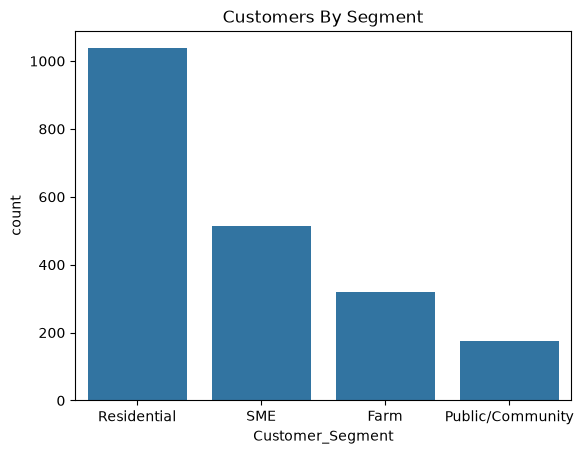

In [863]:
sns.countplot(
    data=df,
    x="Customer_Segment")

plt.title("Customers By Segment")

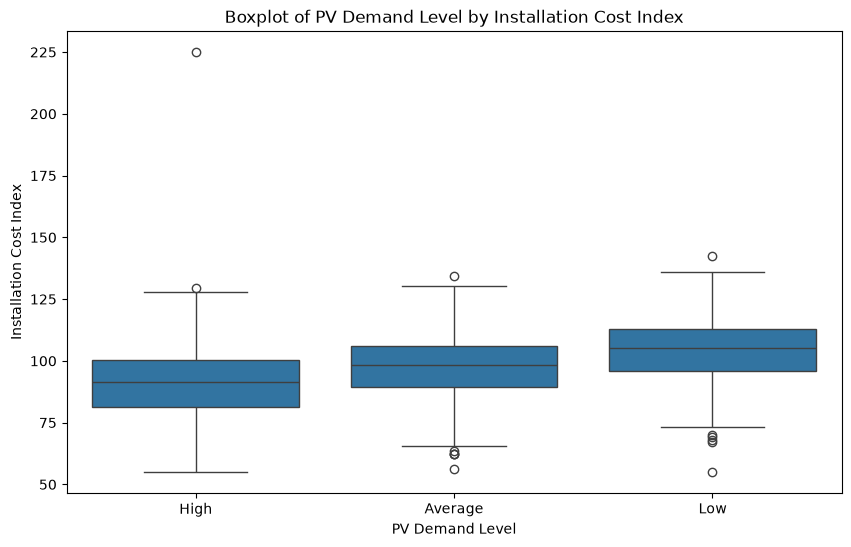

In [864]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["PV_Demand_Level"],
    y= df["Install_Cost_Ind"]
)
   

plt.title("Boxplot of PV Demand Level by Installation Cost Index" )
plt.xlabel("PV Demand Level")
plt.ylabel("Installation Cost Index")

plt.show()

Show analysis of the Target - PV_Demand_Level

In [865]:
df["PV_Demand_Level"].value_counts(normalize=True)

PV_Demand_Level
Average    0.476773
Low        0.263081
High       0.260147
Name: proportion, dtype: float64

Text(0.5, 1.0, 'PV Demand Level')

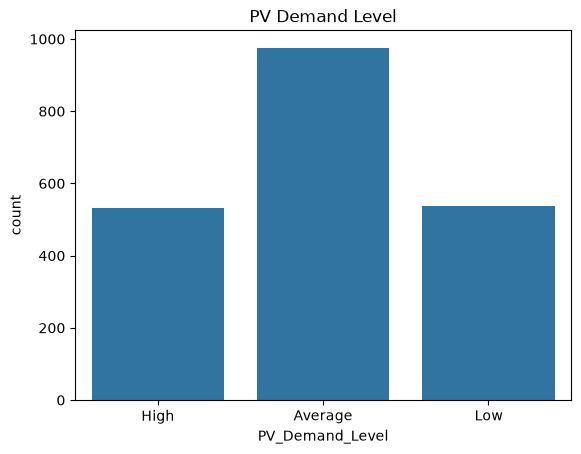

In [866]:
sns.countplot(
    data=df,
    x="PV_Demand_Level")

plt.title("PV Demand Level")

The PV_Demand_Level is the Target class.  

The above chart shows it's reasonably balanced, reducing the chances of model bias during the Machine Learning Section.


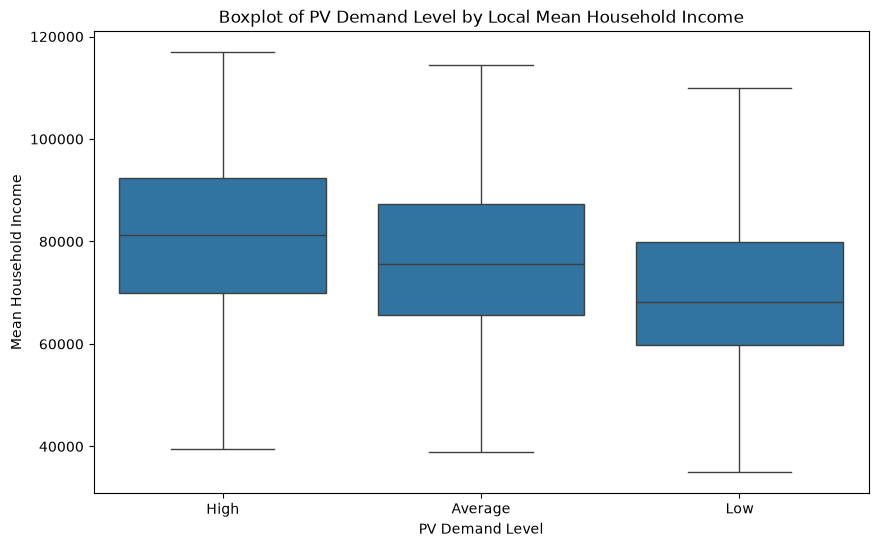

In [867]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["PV_Demand_Level"],
    y= df["Local_Mean_Income"]
)
   

plt.title("Boxplot of PV Demand Level by Local Mean Household Income" )
plt.xlabel("PV Demand Level")
plt.ylabel("Mean Household Income")

plt.show()

The above Boxplot suggests that higher Local Mean Household Income is associated with a higher PV demand level

<Axes: xlabel='Local_Mean_Income', ylabel='Proj_PV_Install_Capacity'>

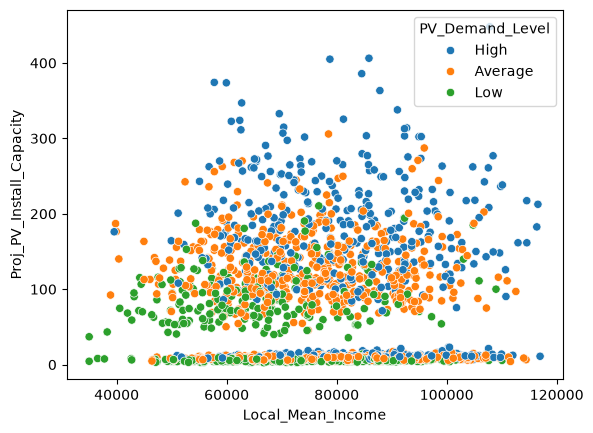

In [868]:
sns.scatterplot(
    data = df,
    x= "Local_Mean_Income",
    y = "Proj_PV_Install_Capacity",
    hue = "PV_Demand_Level"
)

The scatterplot does not suggest a strong relationship between Local Mean Household income and Projected PV Installation Capacity.

However some separation is evident.  High demand observations tend to be associated with larger projected installation capacities.  
    

In [869]:
# create a pivot table
pivot = pd.pivot_table (
    df,
    values="Install_Cost_Ind",
    index="PV_Demand_Level",
    columns="Customer_Segment",
    aggfunc="count",
    margins=True,
    margins_name="Total"
)
pivot

Customer_Segment,Farm,Public/Community,Residential,SME,Total
PV_Demand_Level,,,,,
Average,145,83,508,239,975
High,123,57,195,157,532
Low,51,35,334,118,538
Total,319,175,1037,514,2045


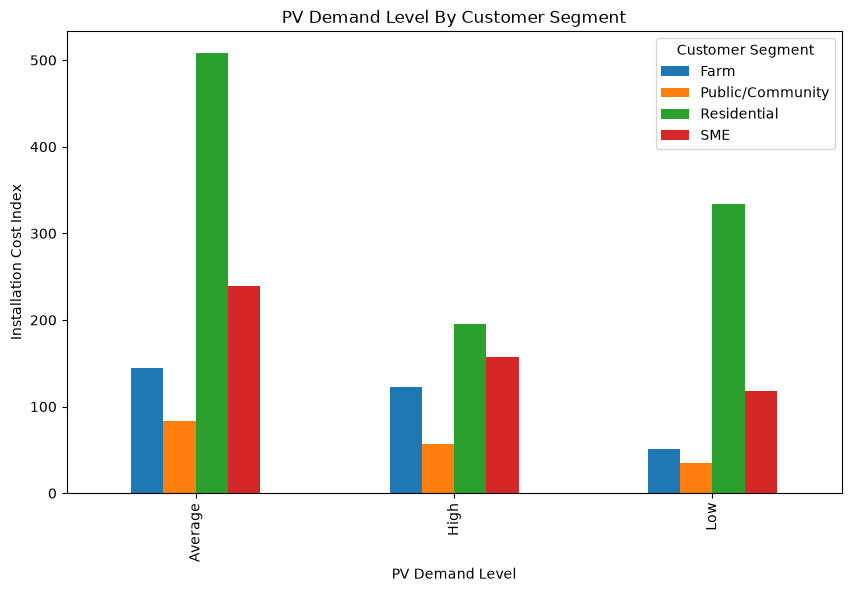

In [870]:
pivot_chart = pivot.drop(
    index="Total",
    errors="ignore").drop(
    columns="Total",
    errors="ignore")

pivot_chart.plot(
    kind="bar",
    figsize=(10,6))

plt.title("PV Demand Level By Customer Segment")
plt.xlabel("PV Demand Level")
plt.ylabel("Installation Cost Index")
plt.legend(title="Customer Segment")

plt.show()

In [871]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Proj_PV_Install_Capacity
Forecast_Year,1.000000,0.246069,-0.327303,0.024359,-0.022868,0.000950,0.003528,-0.529035,-0.015993,0.170901
Local_Mean_Income,0.246069,1.000000,-0.041199,0.181410,-0.054348,0.521044,-0.066936,-0.098144,0.510924,0.008429
Electric_Cost,-0.327303,-0.041199,1.000000,0.005116,0.005873,0.053242,-0.025146,0.161526,0.044168,-0.001077
Solar_Resource,0.024359,0.181410,0.005116,1.000000,0.000228,0.223272,0.015070,0.033105,0.144683,0.064961
Site_Suitability,-0.022868,-0.054348,0.005873,0.000228,1.000000,-0.118008,0.273172,-0.048932,-0.104541,0.471167
Grid_Accessibility,0.000950,0.521044,0.053242,0.223272,-0.118008,1.000000,-0.077964,0.032292,0.445217,-0.059356
Grant_Support,0.003528,-0.066936,-0.025146,0.015070,0.273172,-0.077964,1.000000,-0.069706,-0.097233,0.562597
Install_Cost_Ind,-0.529035,-0.098144,0.161526,0.033105,-0.048932,0.032292,-0.069706,1.000000,0.032718,-0.227902
Planning_Constraint_Ind,-0.015993,0.510924,0.044168,0.144683,-0.104541,0.445217,-0.097233,0.032718,1.000000,-0.134364
Proj_PV_Install_Capacity,0.170901,0.008429,-0.001077,0.064961,0.471167,-0.059356,0.562597,-0.227902,-0.134364,1.000000


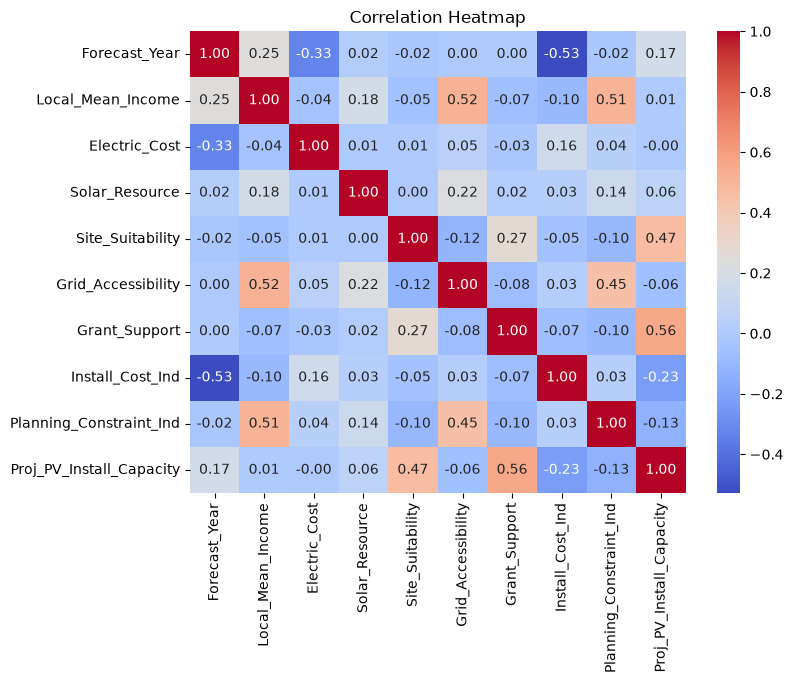

In [872]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    corr_matrix,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Heatmap")

plt.show()

From the above correaltion heatmap, we can see positive correlation between Local_Mean_income (r=0.52) and Grid_Accessibility.

We also see Grant_Support shows a moderate positive relationship (r=0.55) and Projected_PV_Installation_Capacity, suggesting that larger grants may encourage larger-scale solar installations.

Site_Suitability also provides a moderate positive relationship (r=0.48) to Projected_PV_Installation_Capacity, suggesting that more suitable locations will have a higher installation capacity

Forecast_Year shows a moderate negative relationship (r= -0.55) with Installation_Cost_Index, this suggests that costs are projected to decrease over time.  

Installation_Cost_Index also shows a weak negative relationship (r= -0.24) with Projected_PV_Installation_Capacity, suggesting that higher costs may reduce the size of of PV installations  

    

Create a Distribution Chart of Local_Mean_Income and check normality

In [873]:
from scipy import stats 
from scipy.stats import norm # for normality test 

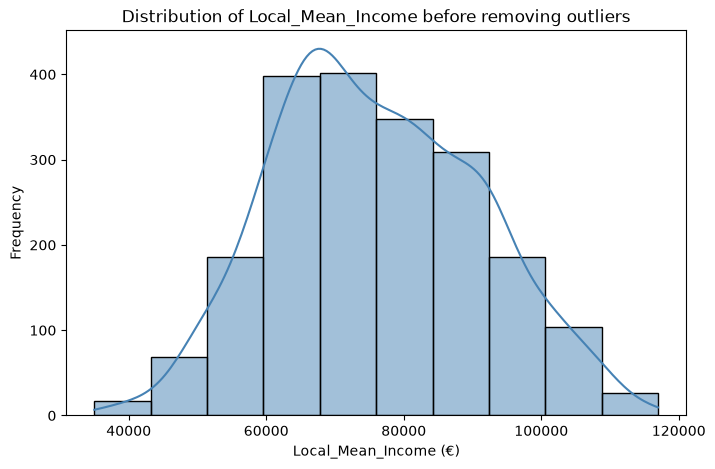

In [874]:
plt.figure(figsize=(8,5) )

sns.histplot(
    data=df,
    x="Local_Mean_Income",
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Local_Mean_Income before removing outliers")
plt.xlabel("Local_Mean_Income (€)")
plt.ylabel("Frequency")


plt.show()

#### Check Normality (using Shapiro_Wilk_test) 

In [875]:
stat, p_value = stats.shapiro(df["Local_Mean_Income"])

print(stat,p_value)

0.9919831504878452 3.62435479171102e-09


In [876]:
if p_value >= 0.05:
    print("Sample appears to be normally distributed.")
else:
    print("Sample does not appear to be normally distributed.")
    

Sample does not appear to be normally distributed.


Drop Outliers in Local_Mean_Income using the IQR Method

In [877]:
Before_Removal = len(df["Local_Mean_Income"])
print(Before_Removal)

2045


In [878]:
Q1 = df["Local_Mean_Income"].quantile(0.25)
Q3 = df["Local_Mean_Income"].quantile(0.75)
IQR = Q3 - Q1
print("Q1= " , Q1)
print("Q3= " , Q3)
print("IQR= " , IQR)

Q1=  64883.24
Q3=  87283.49
IQR=  22400.250000000007


In [879]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("lower_bound =  " , lower_bound)
print("upper_bound =  " , upper_bound)

lower_bound =   31282.864999999983
upper_bound =   120883.86500000002


Remove the lower and upper bounds

In [880]:
df = df[
    (df["Local_Mean_Income"] >= lower_bound) &
     (df["Local_Mean_Income"] <= upper_bound)
      ]

In [881]:
df["Local_Mean_Income"].describe()

count      2045.000000
mean      76052.585428
std       15069.550246
min       35000.000000
25%       64883.240000
50%       74850.580000
75%       87283.490000
max      116976.500000
Name: Local_Mean_Income, dtype: float64

In [882]:
After_Removal = len(df["Local_Mean_Income"])
print(After_Removal)

2045


The IQR method was applied to identify potential outliers with Local_Mean_Income.

However, no observations fell outside the lower and upper IQR thresholds.  This suggests that i had already addressed the outliers earlier in data cleaning stage and no further removal was required.  